**import necessary libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

**Load dataset**

In [ ]:
df = pd.read_csv('/content/PhiUSIIL_Phishing_URL_Dataset.csv')

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [ ]:
df.tail()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
235790,660997.txt,https://www.skincareliving.com,29,www.skincareliving.com,22,0,com,100.000000,1.000000,0.522907,...,1,0,1,51,7,21,187,2,191,1
235791,77185.txt,https://www.winchester.gov.uk,28,www.winchester.gov.uk,21,0,uk,100.000000,0.785714,0.028555,...,1,0,0,50,1,7,88,0,31,1
235792,622132.txt,https://www.nononsensedesign.be,30,www.nononsensedesign.be,23,0,be,100.000000,1.000000,0.003319,...,0,0,1,27,10,30,58,2,67,1
235793,7503962.txt,https://patient-cell-40f5.updatedlogmylogin.wo...,55,patient-cell-40f5.updatedlogmylogin.workers.dev,47,0,dev,28.157537,0.465116,0.000961,...,0,0,0,0,0,3,0,0,0,0
235794,384822.txt,https://www.alternativefinland.com,33,www.alternativefinland.com,26,0,com,100.000000,1.000000,0.522907,...,0,0,1,21,6,18,256,0,261,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation

**Target distribution**

In [ ]:
print(df['label'].value_counts())

print("\nPercentage Distribution:")

print(df['label'].value_counts(normalize=True) * 100)

label
1    134850
0    100945
Name: count, dtype: int64

Percentage Distribution:
label
1    57.189508
0    42.810492
Name: proportion, dtype: float64


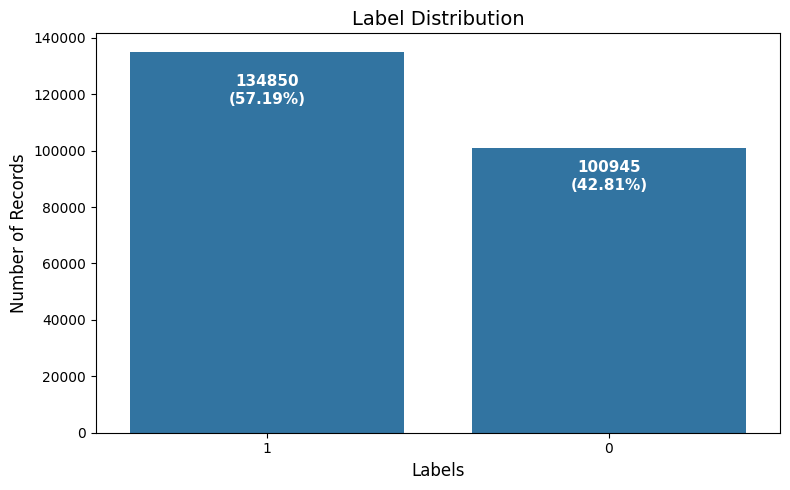

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate counts and percentages
label_counts = df['label'].value_counts()
label_percentages = df['label'].value_counts(normalize=True) * 100

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=label_counts.index,
    y=label_counts.values,
    order=label_counts.index
)

# Display count and percentage inside each bar
for i, value in enumerate(label_counts.values):
    ax.text(
        i,
        value * 0.90,
        f'{value}\n({label_percentages.iloc[i]:.2f}%)',
        ha='center',
        va='center',
        fontsize=11,
        color='white',
        fontweight='bold'
    )

plt.title('Label Distribution', fontsize=14)
plt.xlabel('Labels', fontsize=12)
plt.ylabel('Number of Records', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
print("Numerical Columns:")

print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Columns:")

print(df.select_dtypes(include='object').columns.tolist())

Numerical Columns:
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

Categorical Columns:
['FILENAME', 'URL', 'Domain', 'TLD', 'Title']


**Check missing values**

In [ ]:
missing = df.isnull().sum()

print("Total Missing Values:", missing.sum())

print(missing[missing > 0])

Total Missing Values: 0
Series([], dtype: int64)


In [ ]:
df.shape

(235795, 56)

**Check duplicate records**

In [ ]:
print("Exact Duplicate Rows:", df.duplicated().sum())

print("Duplicate URLs:", df['URL'].duplicated().sum())

Exact Duplicate Rows: 0
Duplicate URLs: 425


**Dropping duplicate URL**

In [ ]:
df = df.drop_duplicates(subset='URL', keep='first')

print("Shape after removing repeated URLs:", df.shape)

Shape after removing repeated URLs: (235370, 56)


**Visualize class distribution**

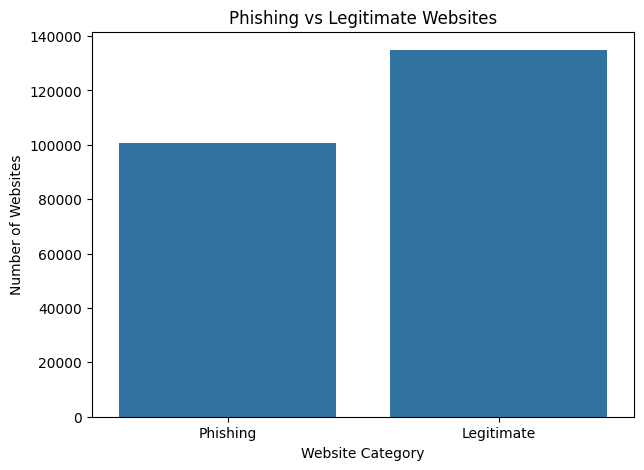

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='label'
)

plt.xticks(
    [0, 1],
    ['Phishing', 'Legitimate']
)

plt.title('Phishing vs Legitimate Websites')
plt.xlabel('Website Category')
plt.ylabel('Number of Websites')

plt.show()

**Analyze numerical feature distributions**

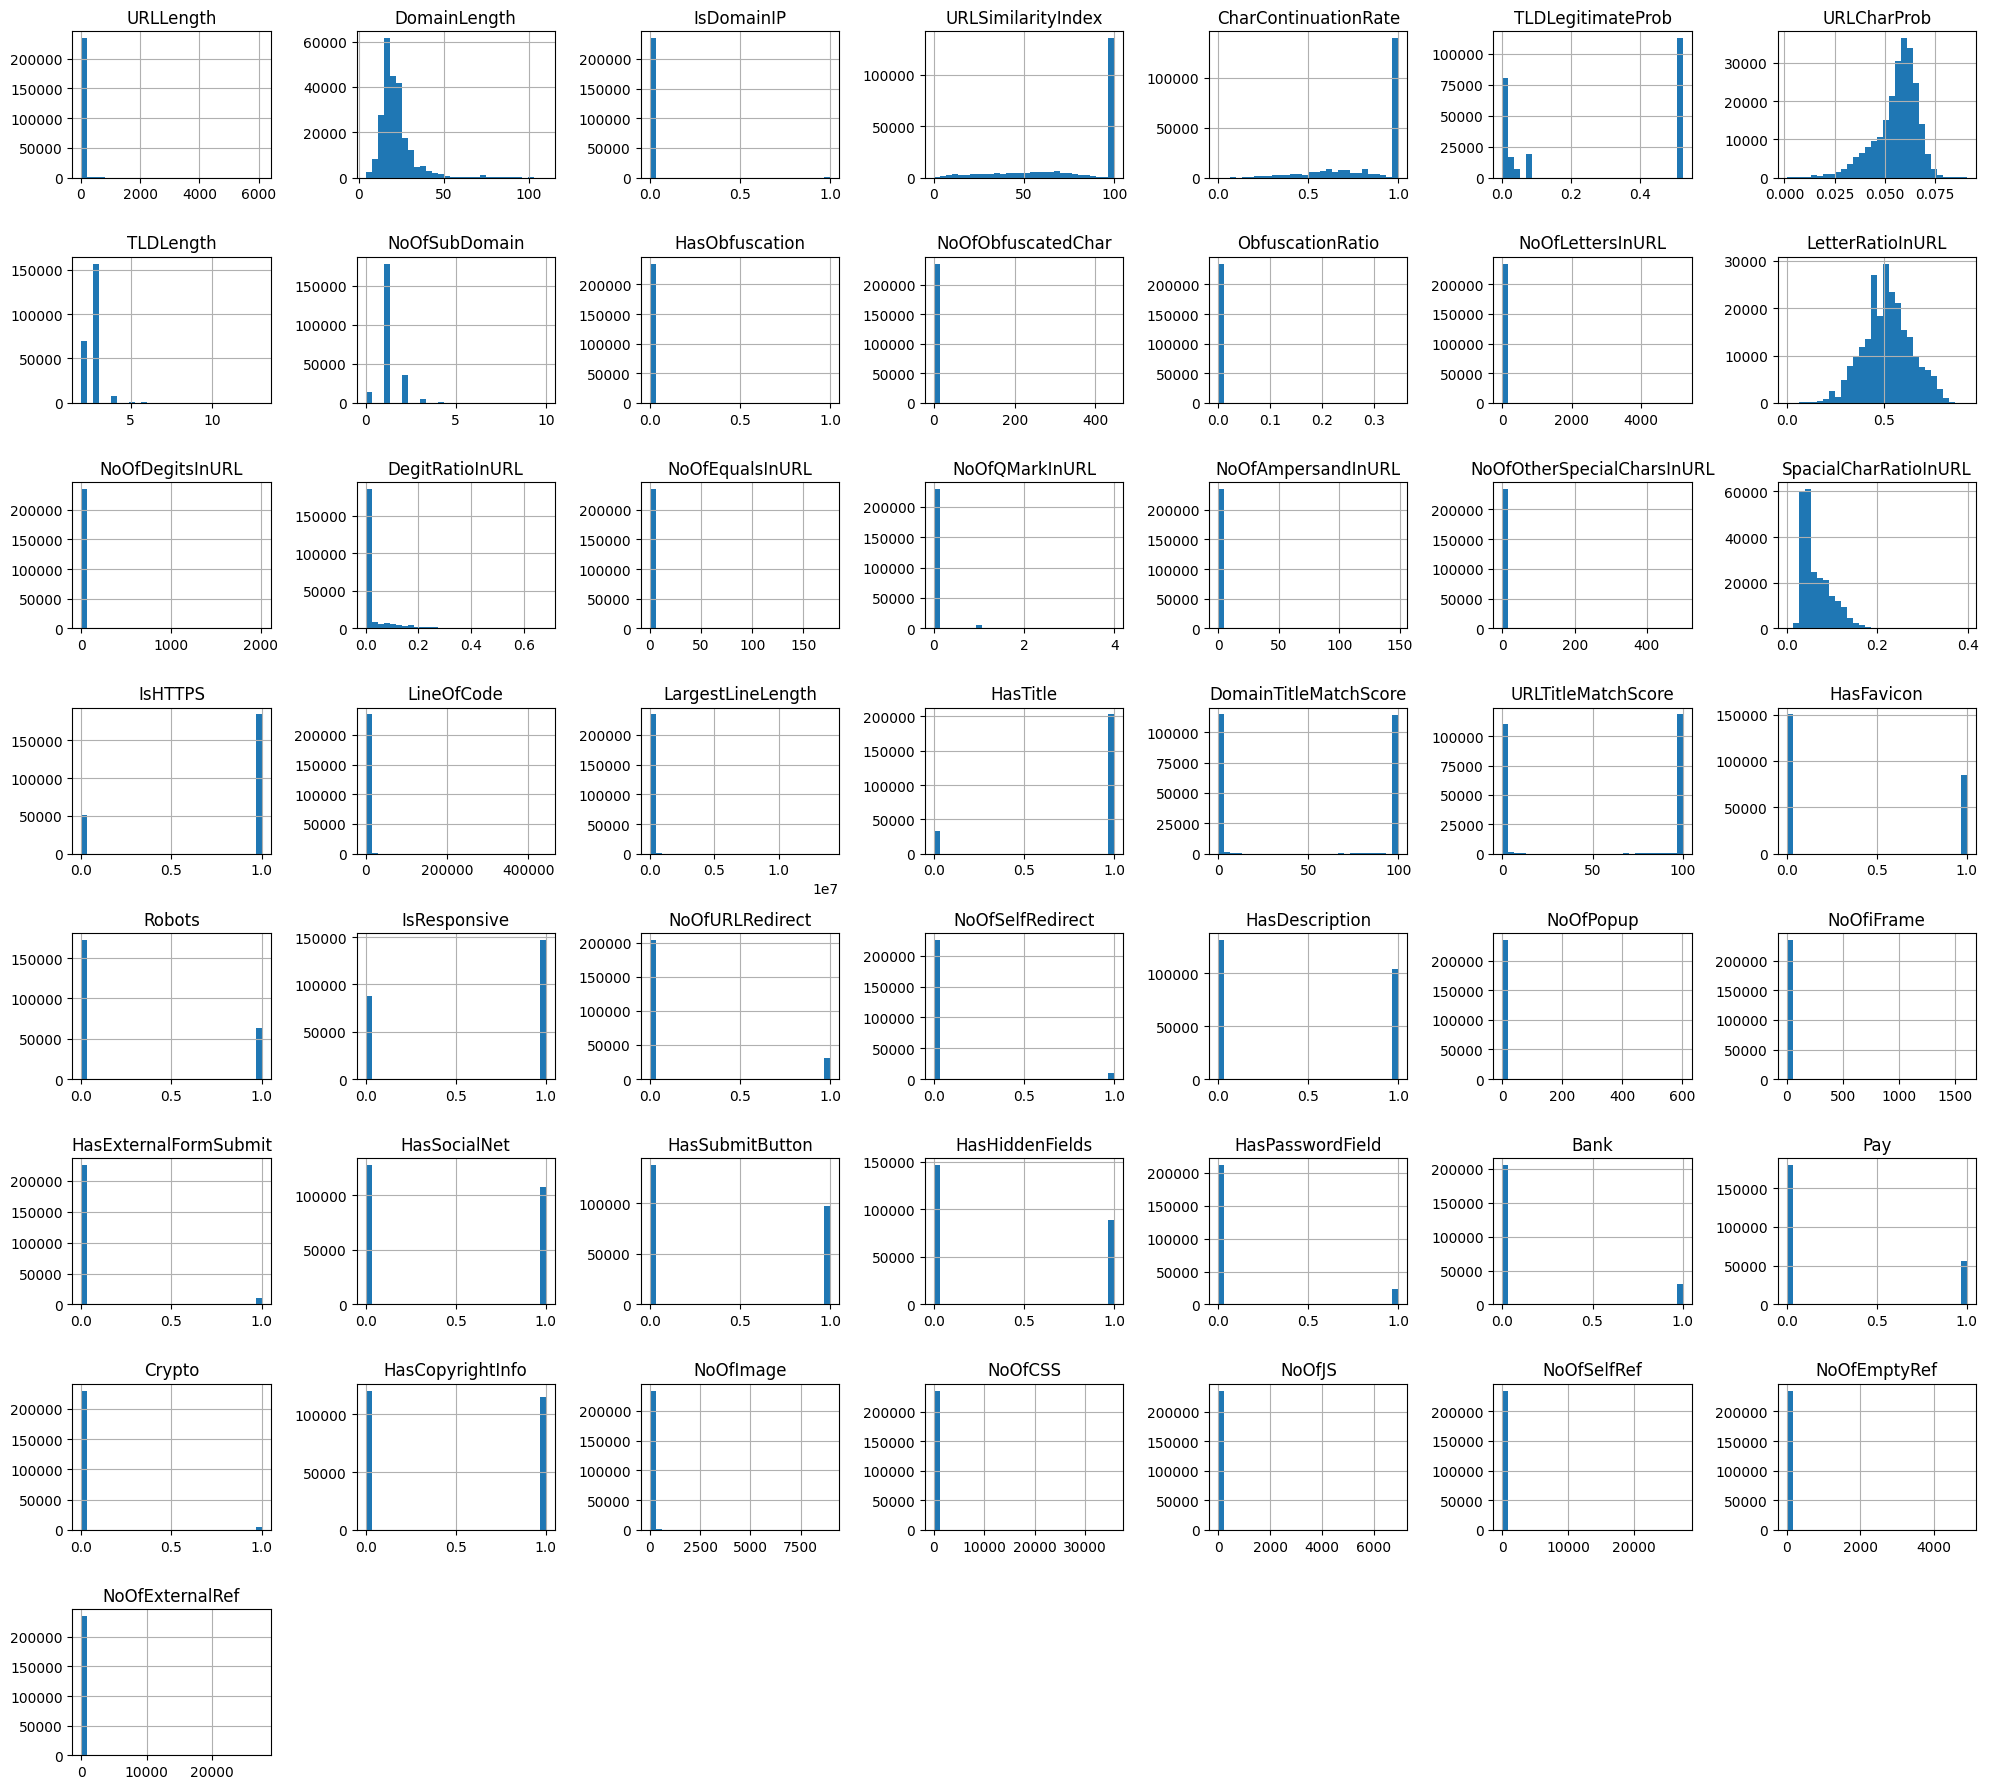

In [ ]:
numeric_features = df.select_dtypes(
    include=np.number
).columns.drop('label')

df[numeric_features].hist(
    figsize=(20, 18),
    bins=30
)

plt.tight_layout()
plt.show()

**Correlation heatmap**

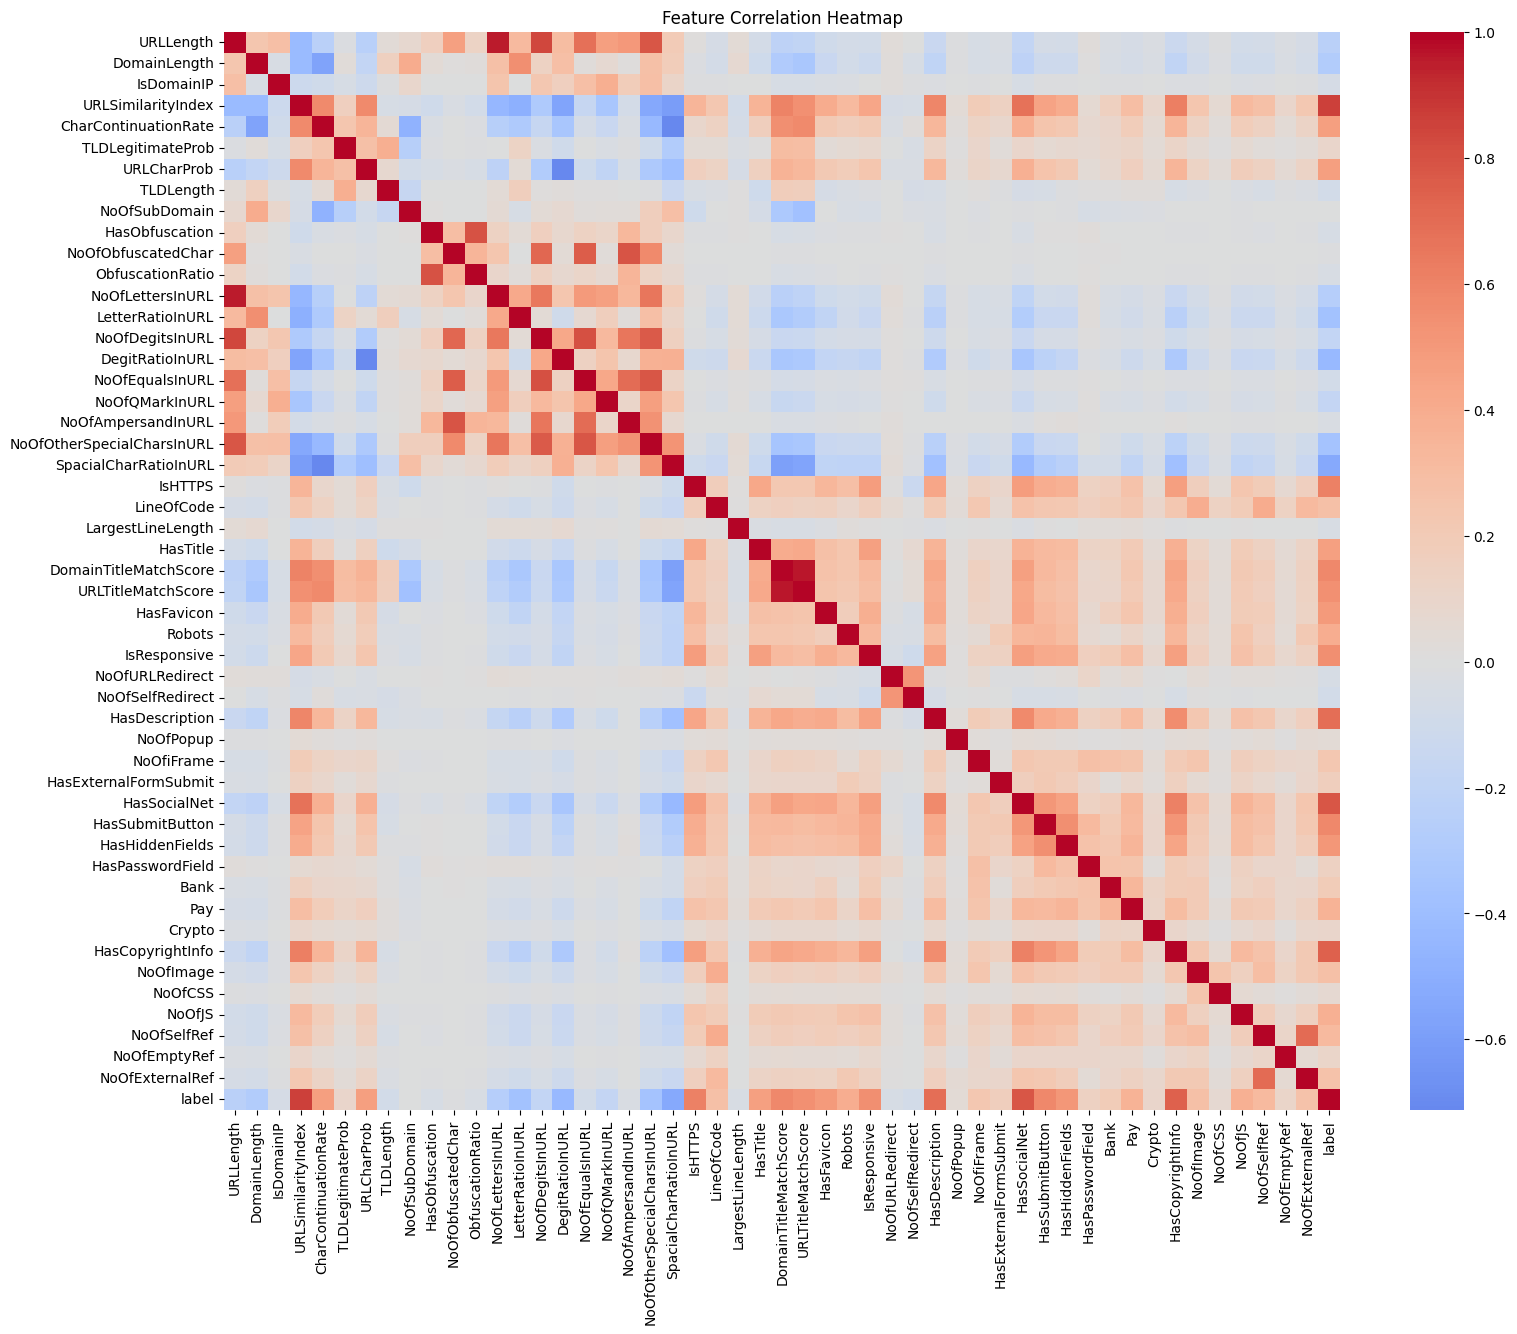

In [ ]:
plt.figure(figsize=(18, 14))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0
)

plt.title('Feature Correlation Heatmap')

plt.show()

**Find the most correlated features with the target**

In [ ]:
target_corr = (
    df.select_dtypes(include=np.number)
    .corr()['label']
    .drop('label')
    .abs()
    .sort_values(ascending=False)
)

print(target_corr.head(15))

URLSimilarityIndex       0.860342
HasSocialNet             0.783882
HasCopyrightInfo         0.743197
HasDescription           0.690011
IsHTTPS                  0.610253
DomainTitleMatchScore    0.584204
HasSubmitButton          0.578816
IsResponsive             0.548977
URLTitleMatchScore       0.538844
SpacialCharRatioInURL    0.533003
HasHiddenFields          0.507715
HasFavicon               0.493607
URLCharProb              0.469521
CharContinuationRate     0.467162
HasTitle                 0.460337
Name: label, dtype: float64


**Data preprocessing strategy**

In [ ]:
# Remove non-informative filename
df = df.drop(columns=['FILENAME'])

# Separate features and target
X = df.drop(
    columns=['label', 'URL', 'Domain', 'TLD', 'Title']
)

y = df['label']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nTarget Mapping:")
print("0 = Phishing")
print("1 = Legitimate")

X Shape: (235370, 50)
y Shape: (235370,)

Target Mapping:
0 = Phishing
1 = Legitimate


In [ ]:
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

print("\nFeature Columns:")
print(X.columns.tolist())

Feature Shape: (235370, 50)
Target Shape: (235370,)

Target Distribution:
label
1    134850
0    100520
Name: count, dtype: int64

Feature Columns:
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfE

**Train-test split**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data: (188296, 50)
Testing Data: (47074, 50)

Training Target Distribution:
label
1    107880
0     80416
Name: count, dtype: int64

Testing Target Distribution:
label
1    26970
0    20104
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

**Logistic regression**

In [ ]:
lr_model = Pipeline([
    ('scaler', StandardScaler()),

    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


**Decision tree**

In [ ]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree Training Completed!")

Decision Tree Training Completed!


**Random Forest Classifier**

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


**Model evaluation function**

In [ ]:
def evaluate_model(model, X_test, y_test, model_name):

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        pos_label=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        pos_label=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        pos_label=0
    )

    print("\n", "=" * 55)
    print(model_name)
    print("=" * 55)

    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)

    print("\nClassification Report:")

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=['Phishing', 'Legitimate']
    ))

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Phishing', 'Legitimate']
    )

    disp.plot(cmap='Blues')

    plt.title(f'{model_name} Confusion Matrix')

    plt.show()

    return {
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    }

**Evaluate Logistic Regression**


Logistic Regression
Accuracy : 0.9999362705527467
Precision: 1.0
Recall   : 0.9998507759649821
F1 Score : 0.9999253824151225

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     20104
  Legitimate       1.00      1.00      1.00     26970

    accuracy                           1.00     47074
   macro avg       1.00      1.00      1.00     47074
weighted avg       1.00      1.00      1.00     47074



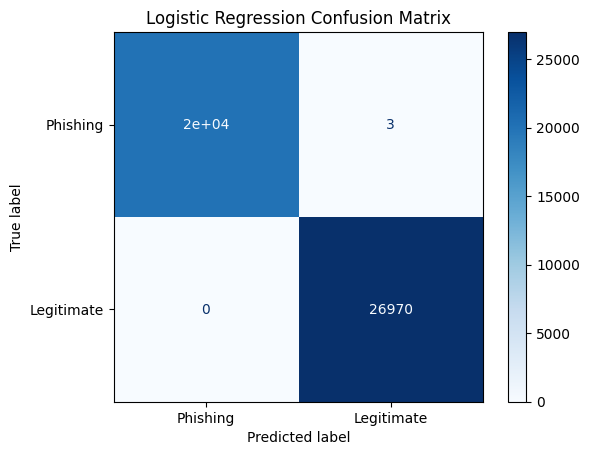

In [ ]:
lr_result = evaluate_model(
    lr_model,
    X_test,
    y_test,
    'Logistic Regression'
)

**Evaluate Decision Tree**


Decision Tree
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     20104
  Legitimate       1.00      1.00      1.00     26970

    accuracy                           1.00     47074
   macro avg       1.00      1.00      1.00     47074
weighted avg       1.00      1.00      1.00     47074



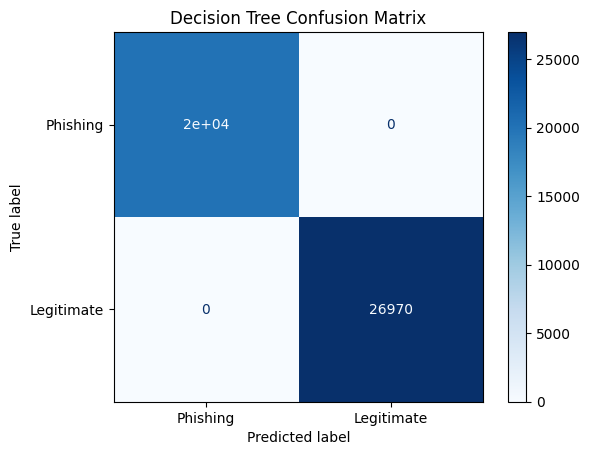

In [ ]:
dt_result = evaluate_model(
    dt_model,
    X_test,
    y_test,
    'Decision Tree'
)

**Evaluate Random Forest**


Random Forest
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     20104
  Legitimate       1.00      1.00      1.00     26970

    accuracy                           1.00     47074
   macro avg       1.00      1.00      1.00     47074
weighted avg       1.00      1.00      1.00     47074



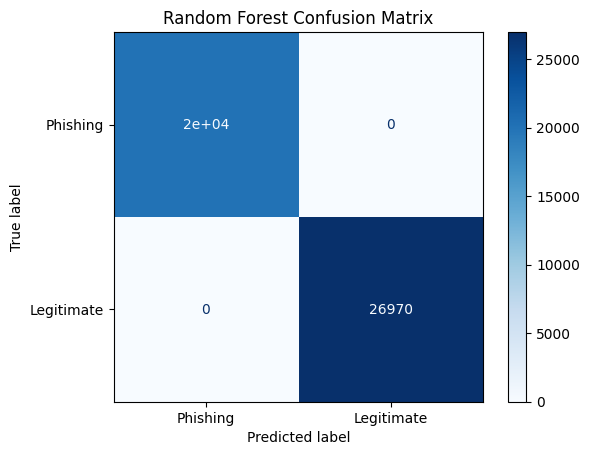

In [ ]:
rf_result = evaluate_model(
    rf_model,
    X_test,
    y_test,
    'Random Forest'
)

**Compare all models**

In [ ]:
results = pd.DataFrame([
    lr_result,
    dt_result,
    rf_result
])

results = results.sort_values(
    by='F1 Score',
    ascending=False
)

print(results.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1 Score
      Decision Tree  1.000000        1.0 1.000000  1.000000
      Random Forest  1.000000        1.0 1.000000  1.000000
Logistic Regression  0.999936        1.0 0.999851  0.999925


**Visualize model comparison**

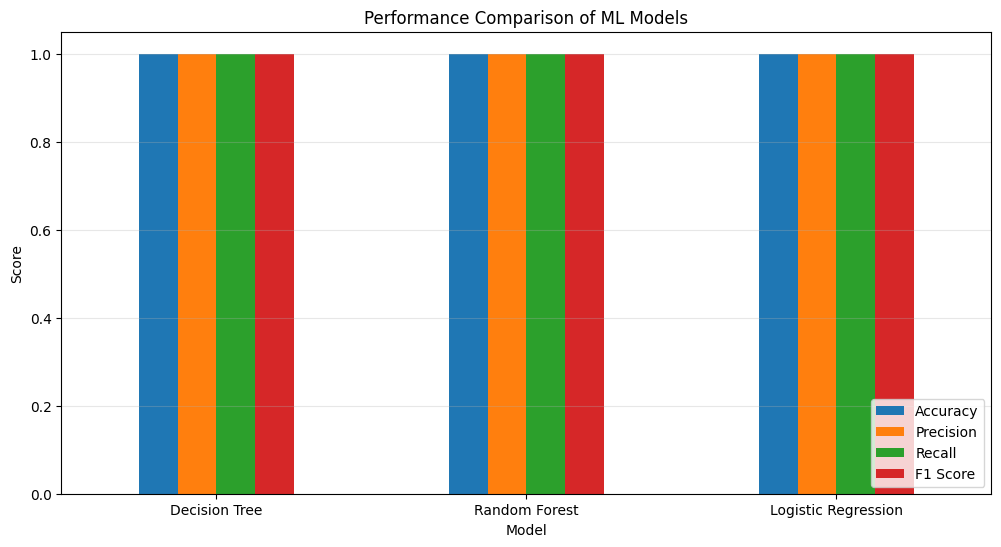

In [ ]:
metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score'
]

results_plot = results.set_index('Model')[metrics]

results_plot.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Performance Comparison of ML Models')

plt.ylabel('Score')
plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.legend(loc='lower right')

plt.grid(axis='y', alpha=0.3)

plt.show()

**Import cross-validation functions**

In [ ]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

**Define cross-validation**

In [ ]:
from sklearn.metrics import make_scorer



cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',

    'precision_phishing': make_scorer(
        precision_score,
        pos_label=0
    ),

    'recall_phishing': make_scorer(
        recall_score,
        pos_label=0
    ),

    'f1_phishing': make_scorer(
        f1_score,
        pos_label=0
    )
}

**Run cross-validation**

In [ ]:
models = {
    'Logistic Regression': lr_model,
    'Decision Tree': dt_model,
    'Random Forest': rf_model
}

cv_results = []

for name, model in models.items():

    print(f"\nRunning 5-Fold CV: {name}")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        'Model': name,

        'Accuracy Mean': scores['test_accuracy'].mean(),

        'Phishing Precision Mean':
            scores['test_precision_phishing'].mean(),

        'Phishing Recall Mean':
            scores['test_recall_phishing'].mean(),

        'Phishing F1 Mean':
            scores['test_f1_phishing'].mean(),

        'Phishing F1 Std':
            scores['test_f1_phishing'].std()
    })

    print("Five-fold Phishing F1 Scores:")
    print(scores['test_f1_phishing'])

    print(
        "Average F1:",
        scores['test_f1_phishing'].mean()
    )


Running 5-Fold CV: Logistic Regression
Five-fold Phishing F1 Scores:
[0.99996891 0.99975123 0.99990673 0.99981343 0.99978233]
Average F1: 0.9998445260088753

Running 5-Fold CV: Decision Tree
Five-fold Phishing F1 Scores:
[1.         1.         1.         1.         0.99996891]
Average F1: 0.9999937820612466

Running 5-Fold CV: Random Forest
Five-fold Phishing F1 Scores:
[1.         1.         1.         1.         0.99993782]
Average F1: 0.9999875637358537


**Display cross-validation comparison**

In [ ]:
cv_comparison = pd.DataFrame(cv_results)

print(
    cv_comparison.sort_values(
        by='Phishing F1 Mean',
        ascending=False
    ).to_string(index=False)
)

              Model  Accuracy Mean  Phishing Precision Mean  Phishing Recall Mean  Phishing F1 Mean  Phishing F1 Std
      Decision Tree       0.999995                      1.0              0.999988          0.999994         0.000012
      Random Forest       0.999989                      1.0              0.999975          0.999988         0.000025
Logistic Regression       0.999867                      1.0              0.999689          0.999845         0.000081
